# PCA и SVD на Python

Метод главных компонент (PCA) на примере роста и веса: ищем ось, вдоль которой данные разбросаны сильнее всего, тремя способами (перебором углов, через собственные векторы корреляционной матрицы и через SVD) и проверяем, что ответы совпадают.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # чтобы случайные числа были одинаковыми при каждом запуске

## 1. Данные

Сгенерируем 100 человек:
- **рост** — из нормального распределения со средним 170 см и σ = 8 см;
- **вес** — зависит от роста: `70 + 0.8 · (рост − 170)`, плюс случайный шум с σ = 4 кг. Чем выше человек, тем он в среднем тяжелее, но не строго.

Соберём рост и вес в таблицу `X` размером 100×2: строки — люди, столбцы — признаки.

In [2]:
N = 100
height_mean_true = 170
height_sd_true = 8 # sd - standard deviation
weight_base = 70
coefficient = 0.8
weight_noise_sd = 4

height = np.random.normal(height_mean_true, height_sd_true, N)
weight = weight_base + coefficient*(height - height_mean_true) + np.random.normal(0, weight_noise_sd, N)
X = np.column_stack([height, weight])
print(X.shape)


(100, 2)


Посмотрим на данные: по оси x рост, по оси y вес. Из-за связи между ростом и весом облако точек вытянуто по диагонали — получается наклонный «огурец».

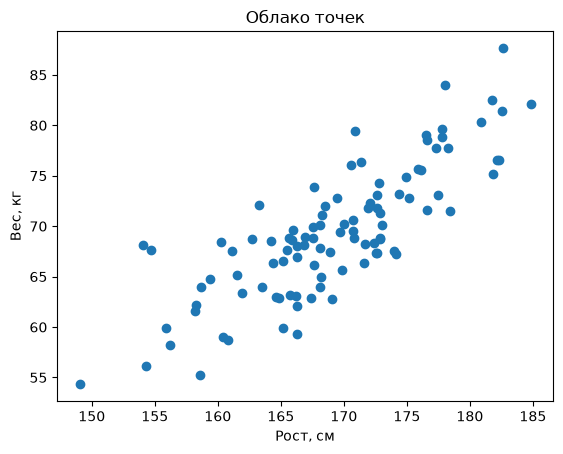

In [3]:
plt.scatter(height, weight)
plt.xlabel('Рост, см')
plt.ylabel('Вес, кг')
plt.title('Облако точек')
plt.show()

## 2. Стандартизация

Рост и вес измеряются в разных единицах (см и кг) и имеют разный разброс. Чтобы ни один признак не перевешивал другой, стандартизируем их: из каждого столбца вычтем его среднее и поделим на его стандартное отклонение:

$$z = \dfrac{x - \bar{x}}{sd}$$

После этого у обоих признаков среднее 0 и sd = 1, а значение показывает, на сколько sd человек отличается от среднего.

Стандартизация по шагам — для каждого столбца отдельно:
```python
height_mean = X.mean(axis=0)[0]
height_sd = X.std(axis=0, ddof=1)[0]
weight_mean = X.mean(axis=0)[1]
weight_sd = X.std(axis=0, ddof=1)[1]

Z1 = (X[:,0]-height_mean)/height_sd
Z2 = (X[:,1]-weight_mean)/weight_sd
Z = np.column_stack([Z1, Z2])
```
NumPy умеет делать это сразу для всех столбцов, поэтому в коде ниже всё записано одной строкой.

In [4]:
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
print(f"Средние Z: {Z.mean(axis=0)}")
print(f"sd Z: {Z.std(axis=0, ddof=1)}")




Средние Z: [-1.28022593e-14 -6.38378239e-16]
sd Z: [1. 1.]


## 3. Крутим ось

Ищем направление, вдоль которого данные разбросаны сильнее всего. Сначала найдём его в лоб — перебором углов.

Ось под углом θ задаётся единичным вектором $v = (\cos θ,\ \sin θ)$. Проекции (тени) всех людей на эту ось: $p = Zv$ — по одному числу на человека. Функция `shadow_var` по углу в градусах считает выборочную дисперсию теней.

Проверка: при 0° ось совпадает с ростом, при 90° — с весом, и в обоих случаях дисперсия должна быть равна 1 (после стандартизации).


In [5]:
def shadow_var(angle_deg):
    angle_rad = np.deg2rad(angle_deg)
    v = np.array([np.cos(angle_rad), np.sin(angle_rad)]) # вектор оси
    p = Z@v # матричное умножение, тени всех людей на ось v
    return np.var(p, ddof=1) # разброс

print(f"Ось 'рост' (0°): {shadow_var(0):.2f} | ось 'вес' (90°): {shadow_var(90):.2f}")

Ось 'рост' (0°): 1.00 | ось 'вес' (90°): 1.00


Посчитаем дисперсию теней для всех углов от 0° до 180°, построим график «угол → дисперсия» и найдём углы с максимальной и минимальной дисперсией.

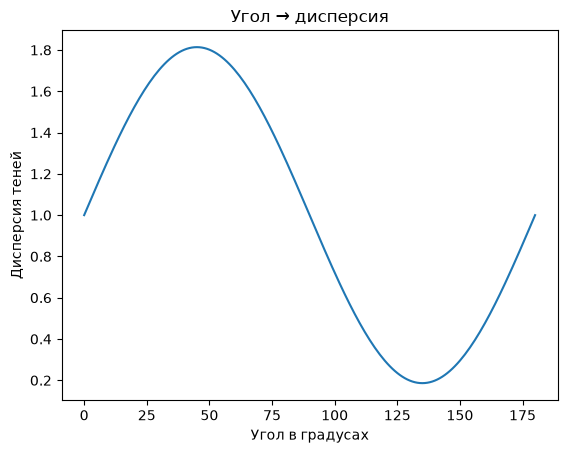

Максимум: угол 45, дисперсия 1.81
Минимум: угол 135, дисперсия 0.19


In [6]:
angles = np.arange(0,181)
variances = []
for angle in angles:
    var = shadow_var(angle)
    variances.append(var)
    
plt.plot(angles,variances)
plt.xlabel('Угол в градусах')
plt.ylabel('Дисперсия теней')
plt.title('Угол → дисперсия')
plt.show()
print(f"Максимум: угол {angles[np.argmax(variances)]}, дисперсия {np.max(variances):.2f}")
print(f"Минимум: угол {angles[np.argmin(variances)]}, дисперсия {np.min(variances):.2f}")

In [7]:
print(f"Например при угле в 30° дисперсия равна {shadow_var(30):.2f}")

Например при угле в 30° дисперсия равна 1.70


In [8]:
print(f"Сумма дисперсий для углов 0° и 90° равна {(shadow_var(0) + shadow_var(90)):.2f}")
print(f"Сумма дисперсий для углов 45° и 135° равна {(shadow_var(45) + shadow_var(135)):.2f}")
print(f"Сумма дисперсий для углов 0° и 45° равна {(shadow_var(0) + shadow_var(45)):.2f}")


Сумма дисперсий для углов 0° и 90° равна 2.00
Сумма дисперсий для углов 45° и 135° равна 2.00
Сумма дисперсий для углов 0° и 45° равна 2.81


Данные сильнее всего растянуты, когда угол составляет 45°. Минимум находится на 135° он перпендикулярен максимуму. Сумма по перпендикулярным осям = 2, по неперпендикулярным больше. 0° и 180° — одна прямая.

## 4. Через собственные векторы корреляционной матрицы

Найдём те же оси без перебора. Корреляционная матрица:

$$C = \dfrac{Z^T Z}{n-1}$$

Посчитаем её вручную и сверим со встроенной `np.corrcoef`.

Собственные векторы $C$ — это главные оси, а собственные числа λ — дисперсии теней вдоль них: для собственного вектора $v^T C v = \lambda$. Найдём их через `np.linalg.eigh` (функция для симметричных матриц). Она возвращает λ **по возрастанию**, а собственные векторы — в **столбцах** матрицы.

In [9]:
C = (Z.T@Z)/(N-1) # ручной способ посчитать корреляционную матрицу
C1= np.corrcoef(X.T) # встроенный способ посчитать корреляционную матрицу
print(f"Совпадают ли результаты 2-ух способов нахождения корреляционной матрицы: {np.allclose(C1, C)}") # проверка равенства

Совпадают ли результаты 2-ух способов нахождения корреляционной матрицы: True


In [10]:
lam, vecs = np.linalg.eigh(C)
print(f"Лямбды:{lam}")
print(f"Векторы главных осей: \n {vecs}")

Лямбды:[0.18620133 1.81379867]
Векторы главных осей: 
 [[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]


Сравним с разделом 3: наибольшее λ должно совпасть с высотой вершины горки, а угол соответствующего собственного вектора — с углом вершины. Угол вектора $(a, b)$ находим через `np.arctan2(b, a)`.

Знак собственного вектора произволен: угол −135° означал бы ту же ось, что и 45°, просто вектор смотрел бы в обратную сторону.

In [11]:
lam_max = np.max(lam)
print(f"Максимальное лямбда: {lam_max:.2f}")
if np.allclose(lam_max, np.max(variances)):
    print("Лямбда найденная по корреляционной матрице совпала с методом из п.3")
else:
    print("Не совпали")
    
angle_pc1 = np.degrees(np.arctan2(vecs[1, 1], vecs[0,1]))
print(f"Угол 1-й главной компоненты: {angle_pc1:.1f}°, лямбда: {lam[1]:.2f}")
angle_pc2 = np.degrees(np.arctan2(vecs[1,0], vecs[0,0]))
print(f"Угол 2-й главной компоненты: {angle_pc2:.1f}°, лямбда: {lam[0]:.2f}")

Максимальное лямбда: 1.81
Лямбда найденная по корреляционной матрице совпала с методом из п.3
Угол 1-й главной компоненты: 45.0°, лямбда: 1.81
Угол 2-й главной компоненты: 135.0°, лямбда: 0.19


## 5. Через SVD

Третий способ — разложить саму матрицу $Z$, без корреляционной матрицы:

$$Z = U \Sigma V^T$$

- столбцы $V$ (правые сингулярные векторы) — главные оси; NumPy возвращает $V^T$ (`Vt`), поэтому в нём оси лежат в **строках**;
- `S` — сингулярные числа σ по убыванию; связь с собственными числами: $\lambda = \dfrac{\sigma^2}{n-1}$;
- $U$ — нормированные тени людей на главные оси: $ZV = U\Sigma$.

`full_matrices=False` — экономная версия SVD: без лишних столбцов $U$ и нулей в $\Sigma$.

Проверим три равенства:
1. λ из SVD совпадают с λ из `eigh` (порядок обратный);
2. оси из SVD совпадают с собственными векторами (с точностью до знака);
3. тени $ZV$ совпадают с $U\Sigma$ (в коде `U * S`: каждый столбец $U$ умножается на своё σ).

In [12]:
U, S, Vt = np.linalg.svd(Z, full_matrices=False) # full_matrices=False - отрезаем лишние столбцы U
print(f"Размер матрицы U: {U.shape}")
print(f"Длина каждого вектора в U: {np.linalg.norm(U, axis=0)}") # проверили длину каждого из векторов
print(f"Транспонированная матрица главных осей Vt: \n {Vt}")
print(f"Массив сингулярных чисел S: {S} \n")


print("#1")
lam_svd = (S**2)/(N-1) # нашли лямбды
print(f"Лямбды: {lam_svd}")
if np.allclose(lam, lam_svd[::-1]): # lam_svd[::-1] - перевернули исходный массив
    print("Вычисленная дисперсия(лямбда) совпадает со значениями лямбда из п.4 \n")
else:
    print("Не совпадают! \n")
    
print("#2")
V = Vt.T
print(f"Матрица главных осей V: \n {V}")
if (np.allclose(V[:,1], vecs[:,0]) or np.allclose(V[:,1], -vecs[:,0])) and (np.allclose(V[:,0], vecs[:,1]) or np.allclose(V[:,0], -vecs[:,1])):
    print("Собственные вектора совпадают с собственными векторами из п.4 \n")
else:
    print("Не совпадают! \n")

print("#3")
P = Z @ Vt.T
US = U*S
if np.allclose(P, US):
    print("P = ZV = US, формула подтверждена, U действительно нормированные тени, а σ — их «масштаб»")
else:
    print("Формула не подтвердилась")

Размер матрицы U: (100, 2)
Длина каждого вектора в U: [1. 1.]
Транспонированная матрица главных осей Vt: 
 [[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]
Массив сингулярных чисел S: [13.40022644  4.29347543] 

#1
Лямбды: [1.81379867 0.18620133]
Вычисленная дисперсия(лямбда) совпадает со значениями лямбда из п.4 

#2
Матрица главных осей V: 
 [[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]
Собственные вектора совпадают с собственными векторами из п.4 

#3
P = ZV = US, формула подтверждена, U действительно нормированные тени, а σ — их «масштаб»


## 6. Доля объяснённой дисперсии

Весь разброс данных — это сумма всех λ. Доля компоненты

$$\frac{\lambda_i}{\lambda_1 + \lambda_2}$$

показывает, какую часть разброса (информации о данных) она несёт.

In [13]:
share1 = (lam_svd[0])/(np.sum(lam_svd))*100
share2 = (lam_svd[1])/(np.sum(lam_svd))*100
print(f"PC1 объясняет {share1:.1f}% дисперсии")
print(f"PC2 объясняет {share2:.1f}% дисперсии")

print(f"Сумма лямбд равна: {np.sum(lam_svd):.1f}")

PC1 объясняет 90.7% дисперсии
PC2 объясняет 9.3% дисперсии
Сумма лямбд равна: 2.0


Первая главная компонента объясняет 90.7% дисперсии, вторая — 9.3%.

Сумма собственных чисел равна 2 - это весь разброс данных, включающий в себя дисперсии каждого признака. Изначально, после стандартизации, дисперсия каждого признака равна 1, поэтому 1 + 1 = 2. Далее мы повернули оси, общий разброс не изменился, а только перераспределился, по главным осям стало 1.81 и 0.19.

Поэтому, вместо двух чисел (рост и вес) про каждого человека можно хранить одно — его проекцию на первую главную компоненту — и потерять меньше 10% информации.

## 7. Сжатие: оставляем одну компоненту

Проверим на деле вывод из раздела 6: оставим про каждого человека одно число вместо двух и посмотрим, сколько потеряем.

**Сжатие.** Для каждого человека запоминаем только тень на первую главную ось, вторую выкидываем.

**Восстановление.** Чтобы снова нарисовать точки на плоскости, откладываем каждую тень вдоль первой оси:

$$\hat{Z} = \underbrace{\sigma_1 u_1}_{\text{тени на 1-ю ось}} \cdot \underbrace{v_1^T}_{\text{направление оси}}$$

Все восстановленные точки ложатся на первую главную ось: каждая — основание перпендикуляра, опущенного из настоящей точки на ось.

**Ошибка.** `Z - Z_hat` — вектор промаха для каждого человека, от восстановленной точки к настоящей. Он направлен поперёк первой оси, а его длина равна тени человека на вторую ось — именно эту координату мы и выкинули.

Чтобы оценить сжатие в целом, складываем квадраты промахов всех людей. Квадраты, потому что:
- промахи в разные стороны не гасят друг друга;
- квадрат длины вектора считается по Пифагору: $x^2 + y^2$;
- только квадраты складываются по перпендикулярным осям (как $3^2 + 4^2 = 5^2$), поэтому для каждой точки тень² + промах² = расстояние² от центра.

In [14]:
U_one = U[:, :1] # первый столбец U: нормированные тени людей на 1-ю главную ось
print(f"Первый столбец U: {U_one[:5]}")
Vt_one = Vt[:1] # первая строка Vt: направление 1-й главной оси
print(f"Первая строка Vt: {Vt_one}")
Z_hat = (S[0]*U_one)@Vt_one  # тени на 1-ю ось × её направление = точки, восстановленные по одной компоненте
print(f"Восстановленная матрица Z_hat: {Z_hat[:5]}")

Первый столбец U: [[-0.01941907]
 [ 0.01816519]
 [-0.07084994]
 [-0.15225458]
 [ 0.02029808]]
Первая строка Vt: [[-0.70710678 -0.70710678]]
Восстановленная матрица Z_hat: [[ 0.18400332  0.18400332]
 [-0.1721223  -0.1721223 ]
 [ 0.67133091  0.67133091]
 [ 1.44267172  1.44267172]
 [-0.19233226 -0.19233226]]


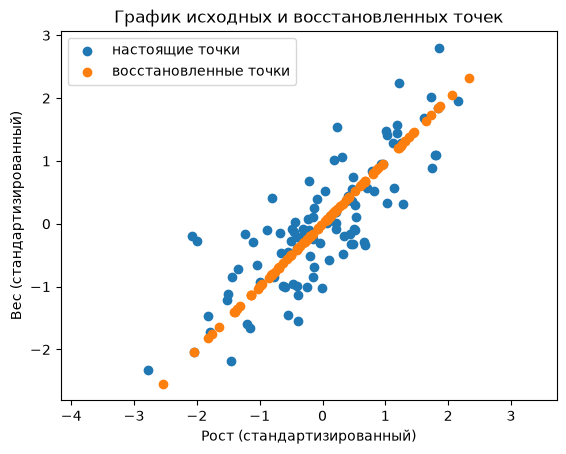

In [15]:
plt.scatter(Z[:,0], Z[:,1], label="настоящие точки")
plt.scatter(Z_hat[:,0], Z_hat[:,1], label="восстановленные точки")
plt.legend()
plt.xlabel("Рост (стандартизированный)")
plt.ylabel("Вес (стандартизированный)")
plt.title("График исходных и восстановленных точек")
plt.axis("equal")
plt.show()


In [16]:
error = Z-Z_hat # насколько мы промахнулись по росту и весу, вектор промаха каждого человека
error_sum = np.sum(error**2) # квадрат длины промаха, сложенный по всем людям
print(f"Сумма квадратов промахов: {error_sum:.2f}")
print(f"σ₂² = {S[1]**2:.2f}") 
if np.allclose(error_sum, S[1]**2):
    print(f"Ошибка сжатия = σ₂² = {error_sum:.2f}")
else:
    print("Не совпадает!")
    
print(f"Ошибка/(N-1) = {error_sum/(N-1):.2f}, λ₂ = {lam_svd[1]:.2f}")

Сумма квадратов промахов: 18.43
σ₂² = 18.43
Ошибка сжатия = σ₂² = 18.43
Ошибка/(N-1) = 0.19, λ₂ = 0.19


Восстановленные точки легли на первую ось, ошибка = σ₂², в среднем на человека = λ₂, потеряли ровно 9.3%

## Выводы

1. Проанализировали данные о росте и весе 100 человек. После стандартизации у обоих признаков среднее 0 и дисперсия 1, и результат больше не зависит от единиц измерения.

2. Нашли главные оси — направления, вдоль которых разброс данных наибольший, — тремя способами: перебором углов, через собственные векторы корреляционной матрицы и через SVD. Все три способа дали одинаковый результат:
   - первая главная ось под углом 45°, дисперсия вдоль неё λ₁ = 1.81;
   - вторая главная ось под углом 135° (перпендикулярно первой), дисперсия λ₂ = 0.19.

   Главная ось идёт по диагонали, потому что рост и вес сильно связаны (корреляция 0.81): высокие люди в среднем тяжелее.

3. Сумма λ равна 2 — это весь разброс данных (по 1 на каждый стандартизированный признак). При повороте осей он не меняется, а только перераспределяется: первая компонента объясняет 90.7% дисперсии, вторая — 9.3%.

4. При сжатии до одной компоненты для каждого человека хранится одно число вместо двух. Ошибка восстановления равна σ₂², то есть потерялись ровно 9.3% дисперсии, которые несла выкинутая компонента. Значит, ошибку сжатия можно знать заранее по сингулярным числам.